<a href="https://colab.research.google.com/github/Gaurav4776608/Data-Cleaning-Processing-and-EDA/blob/main/Handling%20Missing%20Values/Part%202.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Simple Imputer

By the help of Simple Imputer we can fill missing values in numerical as well as in categorical columns.

To fill values in a numerical Univariate column we have 4 methods
1. Mean/Median
2. Filling with random values
3. End of Distribution
4. Arbitrary Values

Mean/Median Values

Here, we replace our missing values with either mean or median of the available data in that column. We may choose either mean or median.

How will we get to know which one to choose?

Use the code plt.hist(df['column_name'], bins = value) this will plot a graph for us now check if that graph is not skewed will use MEAN or else if skewed use MEDIAN.

Advantages:
Simple to use

Disadvantages:
1. Disturb the proper distribution of data
2. Introduction of some outliers
3. Covariance issues

When to use?

When no of missing values in a column is less than 5% of the total data. Also it should follow MCAR (Missing Completely At Random)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [ ]:
df = pd.read_csv('titanic.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
#here we have modified the actual dataset for our easy understanding

df = df.drop(columns = ['PassengerId', 'Pclass', 'Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'])
df['Family'] = df['SibSp']+df['Parch']
df = df.drop(columns = ['SibSp', 'Parch'])

In [ ]:
df.head()

,Survived,Age,Fare,Family
0,0,22.0,7.2500,1
1,1,38.0,71.2833,1
2,1,26.0,7.9250,0
3,1,35.0,53.1000,1
4,0,35.0,8.0500,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Age       714 non-null    float64
 2   Fare      891 non-null    float64
 3   Family    891 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 28.0 KB


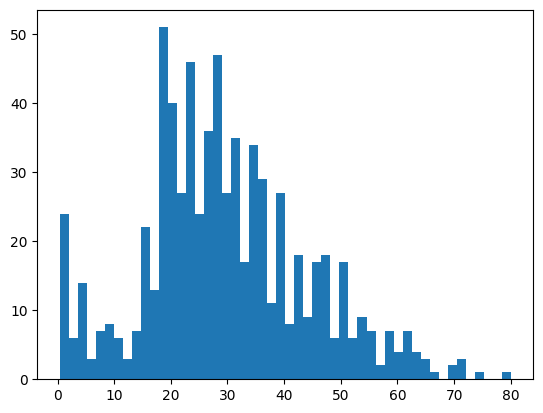

In [ ]:
plt.hist(df['Age'], bins = 50)
plt.show()

In [ ]:
X = df.drop(columns = ['Survived'])
y = df['Survived']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 2)

In [ ]:
imputer1 = SimpleImputer(strategy = 'median')

In [ ]:
original = X_train['Age'].copy()

In [ ]:
X_train[['Age']] = imputer1.fit_transform(X_train[['Age']])
X_test[['Age']] = imputer1.transform(X_test[['Age']])

In [ ]:
X_train

,Age,Fare,Family
30,40.00,27.7208,0
10,4.00,16.7000,2
873,47.00,9.0000,0
182,9.00,31.3875,6
876,20.00,9.8458,0
...,...,...,...
534,30.00,8.6625,0
584,28.75,8.7125,0
493,71.00,49.5042,0
527,28.75,221.7792,0


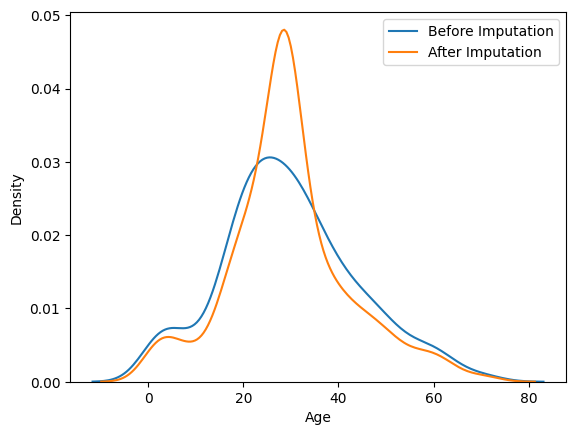

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.kdeplot(original, label='Before Imputation')
sns.kdeplot(X_train['Age'], label='After Imputation')

plt.legend()
plt.show()